# Проект: "Прогнозирование температуры звезды"

Обсерватория "Небо на ладони" хочет опрбовать новый способ для расчета температуры звезды - предсказание с помощью нейронных сетей, вместо старых методов вычисления.

### Цель исследования

Разработать нейронную сеть для предсказания температуры на поверхности звезды

### Основные задачи исследования

Проект распадается на несколько основных задач, требуется провести исследовательский анализ данных, подготовить данные к обучению, тестово обучить базовую нейронную сеть и разработать финальную, которая будет обучаться вместе с перебором гиперпараметров

### Исходные данные

Нам дан датасет на 240 записей с различными характеристиками звезд: температура, светимость(относительно солнца), блеск звезды, радиус(относительно солнца), тип звезды и ее цвет

## Загрузка данных

Для начала подгрузим требуемые библиотеки

In [1]:
!pip install phik -q

In [2]:
pip install optuna -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
!pip install scikit-learn==1.1.3 -q

In [4]:
!pip install torch==1.10.0 -q

In [5]:
import torch
import optuna
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import copy

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from phik import phik_matrix
from phik.report import plot_correlation_matrix

Зададим требуемый константы

In [6]:
RANDOM_STATE = 42
TEST_SIZE = 0.25
torch.manual_seed(42)
np.random.seed(42)

## Предобработка и анализ данных

Напишем класс для анализа данных

In [7]:
class EDA:
    
    def __init__(self, filepath):
        self.filepath = filepath
        try:
            self.df = self.read_data()
            print('Данные загружены')
        except:
            self.df is None
            print('Все плохо')
    
    def read_data(self):
        if '.csv' in self.filepath:
            return pd.read_csv(self.filepath, encoding='utf-8')
        elif 'xlsx' in self.filepath:
            return pd.read_excel(self.filepath, encoding='utf-8')
        
    def intro(self):
        if self.df is None:
            print('Все плохо')
            return
        
        print('Первые пять строк и базовая инфа')
        display(self.df.head(5))
        display(self.df.describe())
        self.df.info()
        
    def feature_display(self, int_cols, dis_cols, cat_cols):
        if self.df is None:
            print('Все плохо')
            return
        
        print('Диаграммы размаха и гистограммы непрерывных признаков')
        for column in int_cols:
            plt.title(column)
            plt.boxplot(self.df[column])
            plt.show()
            
            fig, ax = plt.subplots(figsize=(8, 5))
            sns.histplot(self.df, x=column,
                 kde=True, kde_kws={'bw_method': 0.6}, edgecolor='white', ax=ax)
            ax.set_title(f'Распределение признака\n«{column}»')
            ax.set_xlabel(column)
            ax.set_ylabel('Количество')
            plt.show()
        
        print('Столбчатые диаграммы дискретных признаков')        
        for column in dis_cols:
            plt.title(column)
            plt.bar(self.df[column].value_counts().index, self.df[column].value_counts().values)
            plt.show()
            
        print('Столбчатые диаграммы для категориальных признаков')
        for column in cat_cols:
            counts = self.df[column].value_counts()
            plt.figure(figsize=(10,4))
            sns.barplot(x=counts.sort_values(ascending=False).index, 
                        y=counts.values, 
                        palette="viridis")
            plt.xticks(rotation=90)
            plt.tight_layout()
            plt.title(column)
            plt.show()
        
    def phik_matrix(self,int_cols):
        phik_overview = self.df.phik_matrix(interval_cols=int_cols)
        plt.figure(figsize=(20, 12))
        sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
        plt.title("Матрица корреляций")
        plt.show()

Считаем наши данные

In [8]:
data = EDA('/datasets/6_class.csv')
df_main = data.df

Данные загружены


Теперь ознакомимся с базовой инфой

In [9]:
data.intro()

Первые пять строк и базовая инфа


,Unnamed: 0,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color
0,0,3068,0.002400,0.1700,16.12,0,Red
1,1,3042,0.000500,0.1542,16.60,0,Red
2,2,2600,0.000300,0.1020,18.70,0,Red
3,3,2800,0.000200,0.1600,16.65,0,Red
4,4,1939,0.000138,0.1030,20.06,0,Red


,Unnamed: 0,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type
count,240.00000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,119.50000,10497.462500,107188.361635,237.157781,4.382396,2.500000
std,69.42622,9552.425037,179432.244940,517.155763,10.532512,1.711394
min,0.00000,1939.000000,0.000080,0.008400,-11.920000,0.000000
25%,59.75000,3344.250000,0.000865,0.102750,-6.232500,1.000000
50%,119.50000,5776.000000,0.070500,0.762500,8.313000,2.500000
75%,179.25000,15055.500000,198050.000000,42.750000,13.697500,4.000000
max,239.00000,40000.000000,849420.000000,1948.500000,20.060000,5.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              240 non-null    int64  
 1   Temperature (K)         240 non-null    int64  
 2   Luminosity(L/Lo)        240 non-null    float64
 3   Radius(R/Ro)            240 non-null    float64
 4   Absolute magnitude(Mv)  240 non-null    float64
 5   Star type               240 non-null    int64  
 6   Star color              240 non-null    object 
dtypes: float64(3), int64(3), object(1)
memory usage: 13.2+ KB


Есть лишний стобец с индексацией, его можно убрать

In [10]:
df_main = df_main.drop('Unnamed: 0', axis=1)

Переименуем для удобства названия стобцов

In [11]:
rename = {'Temperature (K)':'temperature',
          'Luminosity(L/Lo)':'luminocity',
          'Radius(R/Ro)':'radius',
          'Absolute magnitude(Mv)':'mv',
          'Star type':'type',
          'Star color':'color'}
df_main = df_main.rename(columns=rename)

In [12]:
data.df = df_main

Распределим признаки по категориям, для дальнейшего анализа

In [13]:
cat_cols = ['color']

dis_cols = ['type']

int_cols = ['temperature',
            'luminocity',
            'radius',
            'mv']

Проверим категориальный столбец на наличие неявных дубликатов

In [14]:
for column in cat_cols:
    print('Значения признака и их упоминания у признака', column)
    display(df_main[column].value_counts())
    print()

Значения признака и их упоминания у признака color


Red                   112
Blue                   55
Blue-white             26
Blue White             10
yellow-white            8
White                   7
white                   3
Yellowish White         3
Blue white              3
Whitish                 2
yellowish               2
Orange                  2
Pale yellow orange      1
Orange-Red              1
Blue white              1
Yellowish               1
White-Yellow            1
Blue-White              1
Blue                    1
Name: color, dtype: int64

Нашлись, давайте исправим их

In [15]:
replace = {
    'Blue White':'Blue-white',
    'Yellowish White':'yellow-white',
    'white':'White',
    'Blue white':'Blue-white',
    'Whitish':'White',
    'yellowish':'yellow',
    'Blue-White':'Blue-white',
    'White-Yellow':'yellow-white',
    'Yellowish':'yellow',
    'Pale yellow orange':'White',
    'Blue':'Blue',
    'Blue white':'Blue-white',
    'Orange-Red':'Orange'
}
df_main['color'] = df_main['color'].str.strip()
df_main['color'] = df_main['color'].replace(replace)

In [16]:
data.df = df_main

Пришло время построить графики и диаграммы

Диаграммы размаха и гистограммы непрерывных признаков


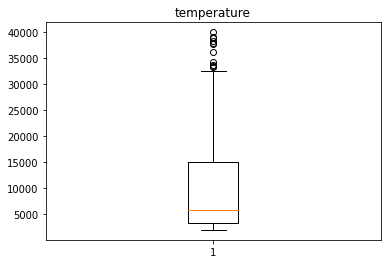

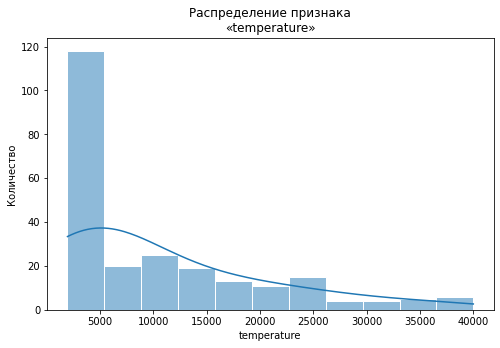

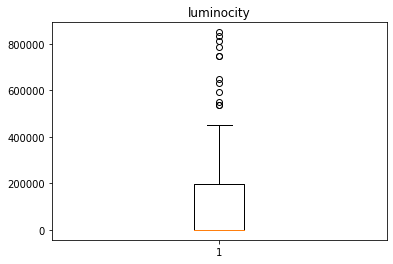

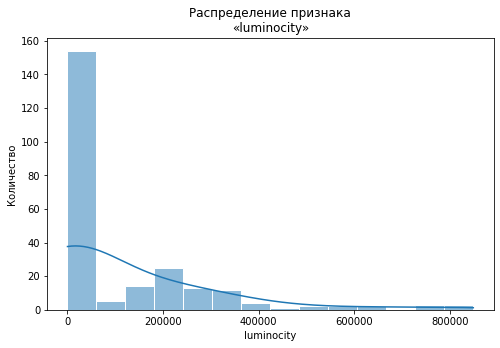

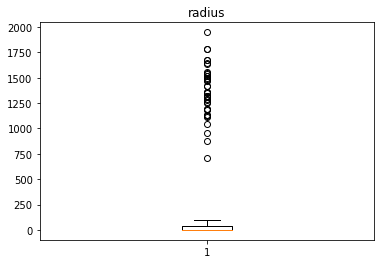

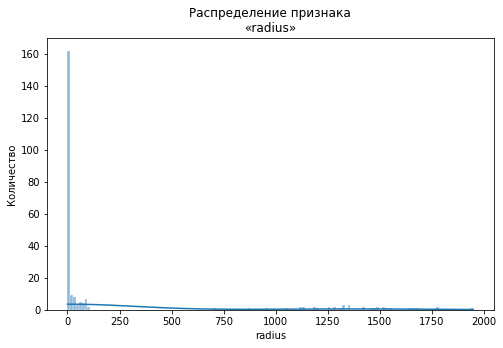

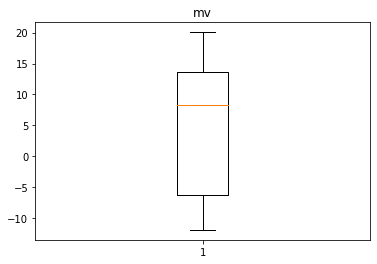

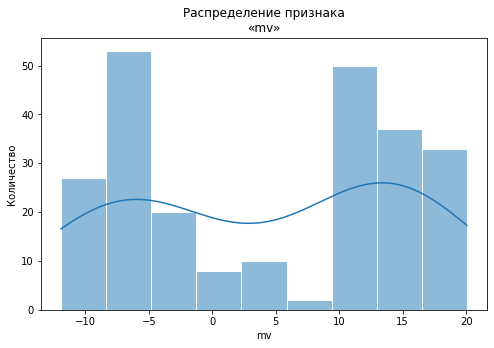

Столбчатые диаграммы дискретных признаков


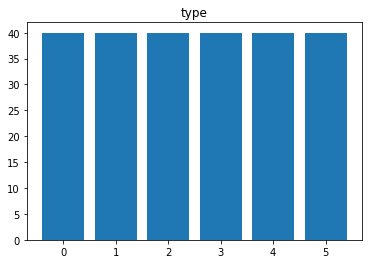

Столбчатые диаграммы для категориальных признаков


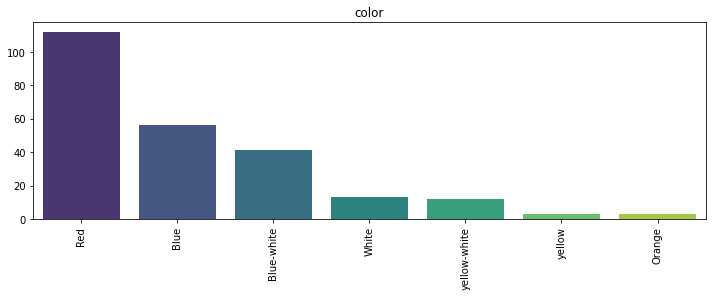

In [17]:
data.feature_display(int_cols,dis_cols,cat_cols)

Все числовые признкаи кроме абсолютной звездной величины имеют ярковыраженную ассиметрию с пиком в нуле у светимости и радиуса и на маленьких значениях для признака температуры. Признак же абсолютной звездной величины имеет два пика в значениях близких к -5 и 10 с "ямой" на нулевых значениях. Дискретный признак типа звезды имеет равномерное распределение. Что до нашего категориального признака - самыми распространенными уветами являются красный, синий и светло-синий

Расчитаем матрицу корреляций

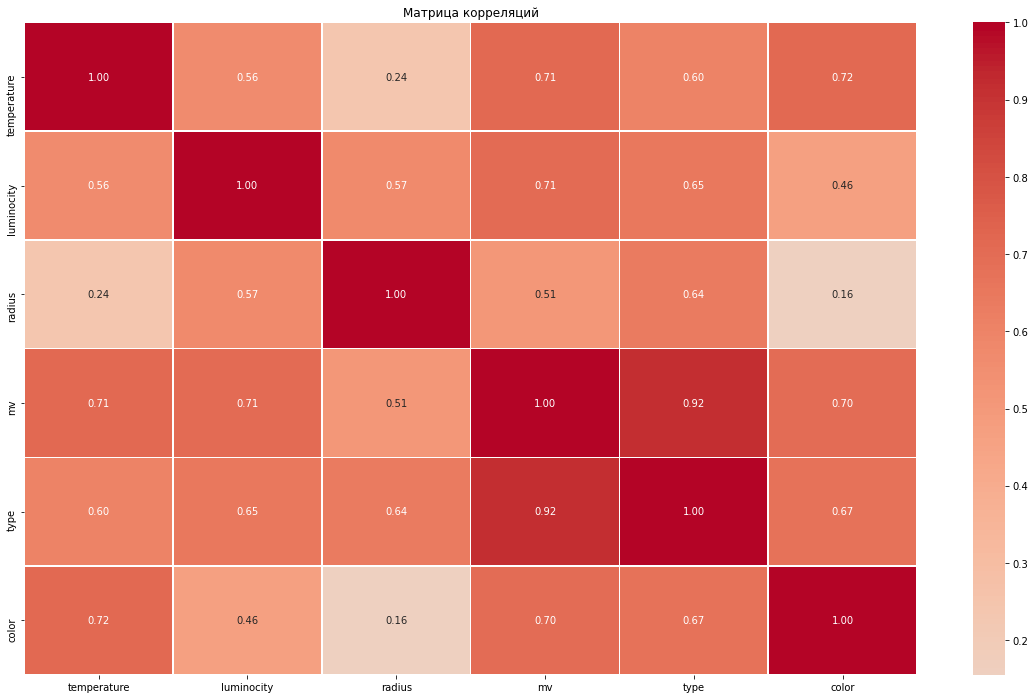

In [18]:
data.phik_matrix(int_cols)

Таргетное значение имеет хорошие корреляции с признаками для обучения, что располагает к хорошему качеству модели, посмотрим, что получится в итоге

Разделим наши данные на выборки и отмасштабируем числовые признаки и закодируем категориальный

In [19]:
X = df_main.drop('temperature',axis=1)
y = df_main['temperature']
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=RANDOM_STATE,test_size=TEST_SIZE,stratify=df_main['color'])

In [20]:
cat_cols = ['color']

dis_cols = ['type']

int_cols = ['luminocity',
            'radius',
            'mv']

In [21]:
def data_transformer(X_train, X_test):
    encoder = OneHotEncoder(sparse=False)
    scaler = StandardScaler()

    X_train_dis = X_train[dis_cols]
    X_train_ohe = encoder.fit_transform(X_train[cat_cols])
    X_train_ohe = pd.DataFrame(X_train_ohe,columns=encoder.get_feature_names_out(), index=X_train.index)
    X_train_scale = scaler.fit_transform(X_train[int_cols])
    X_train_scale = pd.DataFrame(X_train_scale,columns=int_cols, index=X_train.index)
    
    X_test_dis = X_test[dis_cols]
    X_test_ohe = encoder.transform(X_test[cat_cols])
    X_test_ohe = pd.DataFrame(X_test_ohe,columns=encoder.get_feature_names_out(), index=X_test.index)
    X_test_scale = scaler.transform(X_test[int_cols])
    X_test_scale = pd.DataFrame(X_test_scale,columns=int_cols, index=X_test.index)
    
    X_train = X_train_scale.join(X_train_ohe).join(X_train_dis)
    X_test = X_test_scale.join(X_test_ohe).join(X_test_dis)
    
    return X_train, X_test

In [22]:
X_train, X_test = data_transformer(X_train, X_test)

In [23]:
display(X_train)

,luminocity,radius,mv,color_Blue,color_Blue-white,color_Orange,color_Red,color_White,color_yellow,color_yellow-white,type
170,1.248686,2.365443,-1.162093,0.0,0.0,0.0,1.0,0.0,0.0,0.0,5
215,0.411621,-0.453454,-0.856155,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3
1,-0.583468,-0.465089,1.135294,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0
125,-0.583468,-0.465152,1.423180,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0
105,0.739118,-0.385049,-1.023376,1.0,0.0,0.0,0.0,0.0,0.0,0.0,4
...,...,...,...,...,...,...,...,...,...,...,...
29,-0.583468,-0.465359,0.895864,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2
213,-0.544832,-0.452683,-0.684183,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3
61,-0.583468,-0.465020,1.167598,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0
177,0.389864,2.937347,-1.382521,0.0,1.0,0.0,0.0,0.0,0.0,0.0,5


## Построение базовой нейронной сети

Переведем наши даатферймы в тензоры

In [24]:
X_train = torch.FloatTensor(X_train.values)
X_test = torch.FloatTensor(X_test.values)
y_train = torch.FloatTensor(y_train.values)
y_train_log = torch.log1p(y_train)
y_test = torch.FloatTensor(y_test.values)

Так как данных мало стоит использовать неглубокую нейронную сеть, так же во избежание взрыва и затухания градиента будем использовать ReLU в качестве функции активации

In [25]:
class Net(nn.Module):
    def __init__(self, n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_out_neurons):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(n_in_neurons, n_hidden_neurons_1)
        self.fc2 = nn.Linear(n_hidden_neurons_1, n_hidden_neurons_2)
        self.fc3 = nn.Linear(n_hidden_neurons_2, n_out_neurons)

        nn.init.kaiming_normal_(self.fc1.weight, nonlinearity='tanh')
        nn.init.kaiming_normal_(self.fc2.weight, nonlinearity='relu')
        nn.init.xavier_normal_(self.fc3.weight)

    def forward(self, x):
        x = self.fc1(x)
        x = torch.relu(x)
        x = self.fc2(x)
        x = torch.relu(x)
        x = self.fc3(x)
        return x

n_in_neurons = 11
n_hidden_neurons_1 = 25
n_hidden_neurons_2 = 15
n_out_neurons = 1

In [26]:
class EarlyStopping:
    def __init__(self, patience=30, min_delta=0, verbose=False):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, test_loss, model):
        if self.best_loss is None:
            self.best_loss = test_loss
            self.save_checkpoint(model)
        
        elif test_loss < self.best_loss - self.min_delta:
            self.best_loss = test_loss
            self.save_checkpoint(model)
            self.counter = 0
            
        else:
            self.counter += 1
            
            if self.counter >= self.patience:
                self.early_stop = True

    def save_checkpoint(self, model):
        self.best_model_state = copy.deepcopy(model.state_dict())

In [27]:
num_epochs = 10000

early_stopping = EarlyStopping(patience=1000, verbose=True)    
net = Net(n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_out_neurons)
optimizer = torch.optim.Adam(net.parameters(), lr=0.01,weight_decay=0.1)
loss = nn.MSELoss() 

for epoch in range(num_epochs):
    net.train()
    optimizer.zero_grad()
    preds = net.forward(X_train)
    loss_value = loss(preds, y_train_log)
        
    with torch.no_grad():
        train_rmse = torch.sqrt(loss(torch.expm1(preds),y_train))

    loss_value.backward()
        
    optimizer.step()

    net.eval()
    with torch.no_grad():
        test_preds = net.forward(X_test)
        test_mse = loss(torch.expm1(test_preds), y_test)
        test_rmse = torch.sqrt(test_mse)
    if (epoch+1)%100==0:
        print(test_rmse.item(), ' эпоха ', epoch+1)
        
    early_stopping(test_rmse.item(), net)
    
    if early_stopping.early_stop:
        print("Ранняя остановка!")
        break
            
print('RMSE на тестовой выборке: ',test_rmse.item())

/opt/conda/lib/python3.9/site-packages/torch/nn/modules/loss.py:520: UserWarning: Using a target size (torch.Size([192])) that is different to the input size (torch.Size([192, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/opt/conda/lib/python3.9/site-packages/torch/nn/modules/loss.py:520: UserWarning: Using a target size (torch.Size([48])) that is different to the input size (torch.Size([48, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


9901.115234375  эпоха  100
9876.8212890625  эпоха  200
9920.9658203125  эпоха  300
9894.5419921875  эпоха  400
9862.705078125  эпоха  500
9835.8330078125  эпоха  600
9849.880859375  эпоха  700
9844.8525390625  эпоха  800
9846.40234375  эпоха  900
9839.50390625  эпоха  1000
9833.8818359375  эпоха  1100
9828.146484375  эпоха  1200
9842.2744140625  эпоха  1300
9819.63671875  эпоха  1400
9809.8330078125  эпоха  1500
9811.8408203125  эпоха  1600
9808.4345703125  эпоха  1700
9805.1396484375  эпоха  1800
9798.98046875  эпоха  1900
9798.47265625  эпоха  2000
9798.03515625  эпоха  2100
9792.6982421875  эпоха  2200
9807.8486328125  эпоха  2300
9787.662109375  эпоха  2400
9769.470703125  эпоха  2500
9804.580078125  эпоха  2600
9790.87890625  эпоха  2700
9788.2001953125  эпоха  2800
9788.16015625  эпоха  2900
9779.140625  эпоха  3000
9790.373046875  эпоха  3100
9787.1044921875  эпоха  3200
9782.0478515625  эпоха  3300
9785.599609375  эпоха  3400
9786.5615234375  эпоха  3500
9774.169921875  эпоха  

Значение метрики нас не удовлетворяет

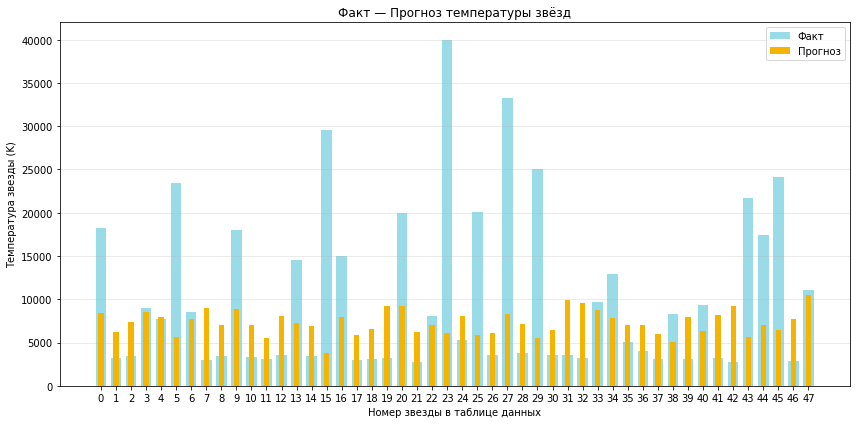

In [28]:
num_stars = len(y_test)
x = np.arange(num_stars)
bar_width = 0.70
plt.figure(figsize=(12, 6))

plt.bar(x,y_test.flatten(),
        width=bar_width, label='Факт', color='#9adbe8')

plt.bar(x,torch.expm1(test_preds).flatten(),
        width=bar_width/2, label='Прогноз', color='#f4b400')

plt.xlabel('Номер звезды в таблице данных')
plt.ylabel('Температура звезды (K)')
plt.title('Факт — Прогноз температуры звёзд')
plt.xticks(x)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Похоже НС предсказывает среднее значение, причем, если поставить скорость обучение поменьше, то она будет предсказывать наоборот значения близкие к нулю, предполагаю это из за маленького размера датасета

## Улучшение нейронной сети

Напишем перебор гиперпараметров, может быть так получится метрика получше

In [29]:
class improved_net(nn.Module):
    def __init__(self, n_in_features, n_hidden_neurons_1, n_hidden_neurons_2, n_out_features, dropout_rate):
        super(improved_net, self).__init__()
        self.fc1 = nn.Linear(n_in_features, n_hidden_neurons_1)
        self.bn1 = nn.BatchNorm1d(n_hidden_neurons_1)
        self.fc2 = nn.Linear(n_hidden_neurons_1, n_hidden_neurons_2)
        self.bn2 = nn.BatchNorm1d(n_hidden_neurons_2)
        self.fc3 = nn.Linear(n_hidden_neurons_2, n_out_features)
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, x):
        x = self.bn1(torch.relu(self.fc1(x)))
        x = self.dropout(x)
        x = self.bn2(torch.relu(self.fc2(x)))
        x = self.dropout(x)
        x = self.fc3(x)
        return x


In [ ]:
def objective(trial):
    dropout_rate = (trial.suggest_float('dropout_rate', 0.01, 0.5))
    batch_size_raw = (trial.suggest_categorical('batch_size', [8, 16, 32]))
    learning_rate = (trial.suggest_float('learning_rate', 0.01, 0.8,log=True))
    weight_decay = (trial.suggest_float('weight_decay', 1e-5, 1e-3, log=True))

    net = improved_net(n_in_features=11, n_hidden_neurons_1=8, n_hidden_neurons_2=4, n_out_features=1, dropout_rate=dropout_rate)
    
    early_stopping = EarlyStopping(patience=1000, verbose=True)    
    
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate, weight_decay=weight_decay)
    
    loss = nn.MSELoss()
    
    num_epochs = 5000

    for epoch in range(num_epochs):
        net.train()
        optimizer.zero_grad()
        preds = net.forward(X_train)
        loss_value = loss(preds, y_train_log)

        loss_value.backward()

        optimizer.step()

        net.eval()
        with torch.no_grad():
            test_preds = net.forward(X_test)
            test_mse = loss(torch.expm1(test_preds), y_test)
            test_rmse = torch.sqrt(test_mse)
        
        early_stopping(test_rmse.item(), net)
    
        if early_stopping.early_stop:
            print("Ранняя остановка!")
            break
                
    return test_rmse
                
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

best_params = study.best_params
print("Лучшие гиперпараметры:", best_params)

[I 2026-01-17 16:45:06,711] A new study created in memory with name: no-name-12553170-51eb-4fa3-ae44-0ea0dca3edc9
[I 2026-01-17 16:45:20,331] Trial 0 finished with value: 9731.484375 and parameters: {'dropout_rate': 0.4116299070210021, 'batch_size': 16, 'learning_rate': 0.30729215028644724, 'weight_decay': 2.3232538123552836e-05}. Best is trial 0 with value: 9731.484375.


Ранняя остановка!


[I 2026-01-17 16:45:33,021] Trial 1 finished with value: 9747.19921875 and parameters: {'dropout_rate': 0.026527910058523937, 'batch_size': 32, 'learning_rate': 0.24733396515367237, 'weight_decay': 6.909072012754542e-05}. Best is trial 0 with value: 9731.484375.


Ранняя остановка!


[I 2026-01-17 16:45:45,516] Trial 2 finished with value: 9879.1884765625 and parameters: {'dropout_rate': 0.10170768412681255, 'batch_size': 8, 'learning_rate': 0.048638074685264814, 'weight_decay': 0.0006803967923869796}. Best is trial 0 with value: 9731.484375.


Ранняя остановка!


Параметры подобраны - устроим финальную проверку

In [ ]:
best_model = improved_net(
    n_in_features=11, 
    n_hidden_neurons_1=8,
    n_hidden_neurons_2=4,
    n_out_features=1, 
    dropout_rate=best_params['dropout_rate']
)

optimizer = torch.optim.Adam(
    best_model.parameters(), 
    lr=best_params['learning_rate'], 
    weight_decay=best_params['weight_decay']
)

early_stopping = EarlyStopping(patience=1000, verbose=True)

for epoch in range(num_epochs):
    best_model.train()
    optimizer.zero_grad()
    preds = best_model(X_train)
    loss = nn.MSELoss()
    loss_value = loss(preds, y_train)
    loss_value.backward()
    optimizer.step()
    
    net.eval()
    with torch.no_grad():
        test_preds = net.forward(X_test)
        test_mse = loss(torch.expm1(test_preds), y_test)
        test_rmse = torch.sqrt(test_mse)
        
    early_stopping(test_rmse.item(), best_model)
    
    if early_stopping.early_stop:
        print("Ранняя остановка!")
        break
                

best_model.eval()
with torch.no_grad():
    test_preds = best_model(X_test)
    test_mse = loss(test_preds, y_test)
    test_rmse = torch.sqrt(test_mse)
    print('RMSE на тестовой ', test_rmse.item())

Данное значение метрики все еще неудовлетворительно

## Выводы

Вначале мы обучили базовую модель, метрика на ней получилась очень плохая, потом мы написали подбор гиперапарметров, который никак ситуации не помог и там тоже получилась неудовлетворительная метрика. Вывод состоит в том, что с данным набором данных не получится добиться адекватной метрики